# **Infer `Cellmask` and `Nucleus`**

***Prior to this notebook, you should have already run through [1.0_image_setup](1.0_image_setup.ipynb).***

In notebooks 1.1 through 1.8, we will go over the implementation of `infer-subc` in the Napari plugin called  `organelle-segmenter-plugin`. The steps outlined in each notebook correlate to the workflow steps from the plugin. Here, you will gain knowledge of what `infer-subc` functions are involved in each of those steps.

The segmentation workflows are completely independent of each other and can be run in any order. The current notebook segments the `cell mask` and `nucleus` based on a multichannel input image. See below for more details on the input image type required. Consider the other versions of notebooks 1.1 outlined below as well.

## **SANDBOX FOR: Improved cell/nuclei segmentation**
<ins>Goals:</ins> Improve cell mask segmentation by implementing a machine learning approach. For comparison, the original masks_C workflow (without nuclei is included first).

Current thought process:
1. Segment nuclei manually from the inverse of a composite image (based on MCZ/ZC updates) -- this is actually very similar or exactly the same as what is done in 1.1a/b (see [NEW_infer-nuc_from-inverse-cyto.ipynb](NEW_infer-nuc_from-inverse-cyto.ipynb) notebook)
2. Input the PM staining and the nuclei segmentation into CellPose
3. POSSIBLY: add a trainable option to improve cyto3 model for iAstrocytes and iNeurons

--------------


---------------------
----------
# **IMPORTS AND LOAD IMAGE**
Details about the functions included in this subsection are outlined in the [`1.0_image_setup`](1.0_image_setup.ipynb) notebook. Please visit that notebook first if you are confused about any of the code included here.

#### &#x1F3C3; **Run code; no user input required**

In [1]:
from pathlib import Path
import os
import seaborn as sns

import numpy as np
import pandas as pd
import napari
from napari.utils.notebook_display import nbscreenshot

from skimage.morphology import binary_dilation, binary_erosion

from infer_subc.core.file_io import (read_czi_image, 
                                     export_inferred_organelle,
                                     list_image_files,
                                     sample_input)
from infer_subc.core.img import *
from infer_subc.organelles.membrane import *
from infer_subc.organelles.nuclei import infer_nuclei_fromcytoplasm

%load_ext autoreload
%autoreload 2
# autoreload can break torch/cellpose ('module torch has no attribute _utils'), so exclude them
%aimport -torch -torchvision -cellpose

#### &#x1F6D1; &#x270D; **User Input Required:**

Please specify the following information about your data: `sample_data_type`, `data_root_path`, `in_data_path`, `im_type`, and `out_data_path`.

In [2]:
### USER INPUT REQUIRED ###
sample_data_type = None


# Edit locations indicated by "USER SPECIFIED".
data_root_path = Path(r"C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data")

in_data_path = data_root_path / "example-images"

im_type = ".tiff"

out_data_path = data_root_path / "202610012_testing-outputs/images_for_figures"

vis_path = data_root_path / "20261029_SR_test-sd"

#### &#x1F3C3; **Run code; no user input required**

In [3]:
# If sample_data_type is set to "neuron_1", "astrocyte", "neuron_2" or "iPSC" then the sample data is used and the directories are set
if sample_data_type != None:
    data_root_path, im_type, in_data_path, out_data_path = sample_input(sample_data_type)

# Create the output directory to save the segmentation outputs in.
if not Path.exists(out_data_path):
    Path.mkdir(out_data_path)
    print(f"making {out_data_path}")

if not Path.exists(vis_path):
    Path.mkdir(vis_path)
    print(f"making {vis_path}")

# Create a list of the file paths for each image in the input folder. Select test image path.
img_file_list = list_image_files(in_data_path,im_type)
pd.set_option('display.max_colwidth', None)
pd.DataFrame({"Image Name":img_file_list})

,Image Name
0,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\02242026_ZS_iPSCs_SOX9NFIA1_BR02_N07_Unmixing_cmle.ome.tiff
1,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N07_Unmixing_cmle.ome.tiff
2,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04092026_ZS_iAtro_day21_SOX9NFIA1_BR05_N11_Unmixing_cmle.ome.tiff
3,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\04102026_iAstrocytesD21_BFP2EEA1_125ng_mTurLAMP1_30ng_OxVenSiT_mAppRab11_30ng_PM_lipoLtx4hr_img11_zstack_Unmixing_decon.ome.tiff
4,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\11192025_iNeurons_day_14_BFP2EEA1_mTurLAMP1_OxVenSiT_mAppRab11_PM_img18_zstack_Unmixing_decon.ome.tiff
5,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
6,C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260813_wtc_ipsc_p47_ALLwell2_img8_Unmixing_cmle.ome.tiff


#### &#x1F6D1; &#x270D; **User Input Required:**

Use the list above to specify which image you wish to analyze based on its index: `test_img_n`

In [4]:
#### USER INPUT REQUIRED ###
test_img_n = 5

#### &#x1F3C3; **Run code; no user input required**

Attempted file (C:/Users/Shannon/Desktop/Cell-nuc-mask_test-data/example-images/20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff) load with reader: aicsimageio.readers.bfio_reader.OmeTiledTiffReader failed with error: No module named 'bfio'


Metadata information
File path: C:\Users\Shannon\Desktop\Cell-nuc-mask_test-data\example-images\20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
File name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome.tiff
Channel 0 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 0
Channel 1 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 1
Channel 2 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 2
Channel 3 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 3
Channel 4 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 4
Channel 5 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 5
Channel 6 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 6
Channel 7 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 7
Channel 8 name: 20260520_wtc_CMs_day21_ALLwell6_img18_Unmixing_cmle.ome :: Channel 8
Channe

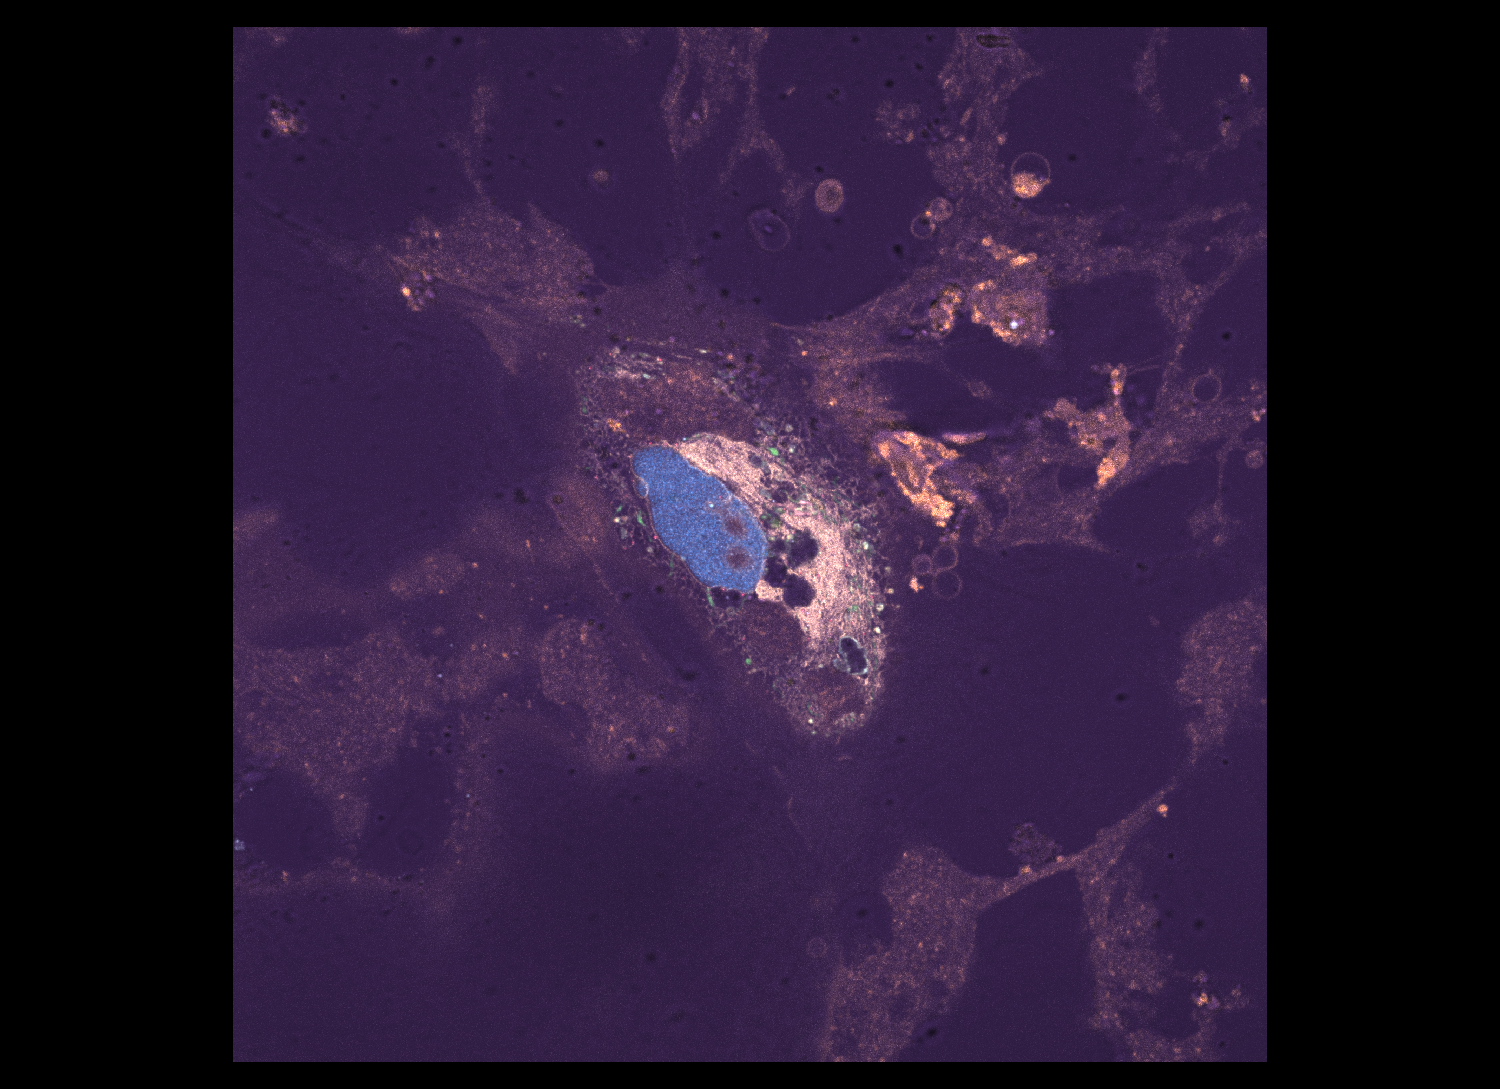

In [5]:
# Read in the image and metadata as an ndarray and dictionary from the test image selected above. 
test_img_name = img_file_list[test_img_n]
img_data,meta_dict = read_czi_image(test_img_name)

# Define some of the metadata features and print them.
channel_names = meta_dict['name']
meta = meta_dict['metadata']['aicsimage']
scale = meta_dict['scale']
channel_axis = meta_dict['channel_axis']
file_path = meta_dict['file_name']
file_name = str(meta_dict['file_name']).split("\\")[-1]

print("Metadata information")
print(f"File path: {file_path}")
print(f"File name: {file_name}")
for i in list(range(len(channel_names))):
    print(f"Channel {i} name: {channel_names[i]}")
print(f"Scale (ZYX): {scale}")
print(f"Channel axis: {channel_axis}")

# open viewer and add images
viewer = napari.Viewer()
color_map = sns.color_palette("Paired").as_hex()
for i in list(range(len(channel_names))):
    # add image to viewer
    viewer.add_image(img_data[i],
                     scale=scale,
                     name=f"Channel {i}",
                     blending='additive',
                     colormap=color_map[i])
viewer.grid.enabled = False
viewer.reset_view()
print("\nProceed to Napari window to view your selected image.")

# screenshot viewer
nbscreenshot(viewer, canvas_only = True)

-----
-----
# **ALTERNATIVE: Cellpose-SAM 3D segmentation of `Cellmask` and `Nucleus`**

This section segments the cell mask and nuclei with the **Cellpose-SAM (`cpsam`) model** that ships with **Cellpose 4**, in true 3D. One generalist model is used for both cells and nuclei (Cellpose 4 no longer has the separate `cyto3`/`nuclei` models). The cell mask is segmented from the plasma membrane channel (default channel 7) or the organelle composite made above, together with the nuclear channel (default channel 1); the nuclei are segmented from the nuclear channel alone.

Cellpose-SAM is much less sensitive to object size than `cyto3`, so a diameter is **optional** (`None` = let the model decide). The channel order is not important and no `channels=` argument is used.

It is an alternative to the `masks_C` workflow below: run **either** this section **or** the steps below, not both. This section stacks and saves its own output.

**Requirements:** Cellpose 4.x. Install once with `pip install "cellpose>=4"` and restart the kernel. This replaces Cellpose 3, so notebooks that use `cyto3`/`nuclei` (e.g. `NEW_infer_masks_cellpose.ipynb`, `NEW_cellpose-training.ipynb`) need their own environment with `cellpose<4`. The model weights are downloaded the first time it runs (internet required). A GPU is strongly recommended for 3D.

In [6]:
# if using a composite of organelles, specify the weights here, else leave them as 0/None
use_composite = True
invert_pm = False
PM_CH = 7
w0 = 0
w1 = 1
w2 = 2
w3 = 2
w4 = 2
w5 = 2
w6 = 4
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

In [9]:
#### USER INPUT REQUIRED ####
CP_NUC_CH = 1             # channel index of the nuclear stain
CP_PM_CH = 7              # channel index of the plasma membrane stain

CP_MODEL = "cpdino" #"cpsam_v2"     # Cellpose-SAM model name ("cpsam_v2" = newest, "cpsam" = original) or a path to your own model file

# Diameters are in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE). Use None to let the model decide
# (recommended first); set a number only if objects are missed or merged.
CP_NUC_DIAMETER = 200    # expected nucleus diameter (pixels in XY)
CP_CELL_DIAMETER = 1000   # expected cell diameter (pixels in XY)

CP_XY_DOWNSAMPLE = 2      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
CP_FLOW_THRESHOLD = 0.1   # DOESNT DO ANYTHING 3D: raise to be more permissive, lower to be stricter
CP_CELLPROB_THRESHOLD = -5  # lower (e.g. -2) to segment more/larger objects
CP_MIN_SIZE_NUC = 2000     # minimum nuclei object size (voxels, downsampled image)
CP_MIN_SIZE_CELL = 5000   # minimum cell object size (voxels, downsampled image)
CP_BATCH_SIZE = 4         # lower if running out of GPU memory

In [10]:
from importlib.metadata import version
import torch
from cellpose import models
from skimage.transform import resize

if int(version('cellpose').split('.')[0]) < 4:
    raise ImportError('The Cellpose-SAM model needs Cellpose 4 or newer. Run: pip install "cellpose>=4" and restart the kernel.')

use_gpu = torch.cuda.is_available()
print(f'Cellpose {version("cellpose")}; using GPU: {use_gpu}')
if not use_gpu:
    print('No GPU found: 3D Cellpose-SAM will be very slow. Consider a larger CP_XY_DOWNSAMPLE.')

def _prep(vol, factor):
    """rescale intensities to 0-1 and shrink XY by `factor` (ZYX in, ZYX out)"""
    vol = np.asarray(vol, dtype=np.float32)
    p1, p99 = np.percentile(vol, (1, 99.8))
    vol = np.clip((vol - p1) / (p99 - p1 + 1e-8), 0, 1)
    if factor != 1:
        vol = resize(vol, (vol.shape[0], round(vol.shape[1] / factor), round(vol.shape[2] / factor)),
                     order=1, anti_aliasing=True).astype(np.float32)
    return vol

def _restore(labels, shape):
    """upsample a label volume back to `shape` (nearest neighbour)"""
    if labels.shape != shape:
        labels = resize(labels, shape, order=0, anti_aliasing=False, preserve_range=True)
    return labels.astype(np.uint16)

if use_composite:
    pm_vol = _prep(composite, CP_XY_DOWNSAMPLE)     # ZYX
else:
    pm_vol = _prep(img_data[CP_PM_CH], CP_XY_DOWNSAMPLE)     # ZYX
nuc_vol = _prep(img_data[CP_NUC_CH], CP_XY_DOWNSAMPLE)   # ZYX
out_shape = img_data[CP_NUC_CH].shape
anisotropy = scale[0] / (scale[1] * CP_XY_DOWNSAMPLE)    # Z step relative to XY pixel size

common = dict(do_3D=True, z_axis=0, anisotropy=anisotropy,
              flow_threshold=CP_FLOW_THRESHOLD, cellprob_threshold=CP_CELLPROB_THRESHOLD,
              batch_size=CP_BATCH_SIZE)

# one Cellpose-SAM model is used for both cells and nuclei
if str(CP_MODEL).lower().endswith(('.pt', '.pth')) or Path(str(CP_MODEL)).exists():
    if not Path(CP_MODEL).exists():
        raise FileNotFoundError(f'Model file not found: {CP_MODEL}')
# If Python's own downloader is blocked (URLError / connection forcibly closed), fetch the weights with curl instead
if CP_MODEL in models.MODEL_NAMES and not (models.MODEL_DIR / CP_MODEL).exists():
    import subprocess
    models.MODEL_DIR.mkdir(parents=True, exist_ok=True)
    print(f'Downloading {CP_MODEL} (~1.2 GB) ...')
    subprocess.run(['curl', '-L', '--fail', '-o', str(models.MODEL_DIR / CP_MODEL),
                    models._MODEL_URL + CP_MODEL], check=True)
sam_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_MODEL))

# nuclei: single channel (ZYX)
nuc_raw = sam_model.eval(nuc_vol, diameter=CP_NUC_DIAMETER, min_size=CP_MIN_SIZE_NUC, **common)[0]

# cells: membrane/composite + nuclei as a 2-channel ZYXC volume (channel order does not matter)
cell_in = np.stack([pm_vol, nuc_vol], axis=-1)
cell_raw = sam_model.eval(cell_in, diameter=CP_CELL_DIAMETER, channel_axis=3,
                          min_size=CP_MIN_SIZE_CELL, **common)[0]

cellmask_obj = _restore(cell_raw, out_shape)
nuc_all = _restore(nuc_raw, out_shape)

# Give each nucleus the label of the cell it overlaps most; drop nuclei that are not inside any cell.
nuc_obj = np.zeros_like(nuc_all)
inside = (nuc_all > 0) & (cellmask_obj > 0)
if inside.any():
    pairs, counts = np.unique(np.stack([nuc_all[inside], cellmask_obj[inside]]), axis=1, return_counts=True)
    best_cell, best_count = {}, {}
    for (n, c), k in zip(pairs.T, counts):
        if k > best_count.get(n, 0):
            best_cell[n], best_count[n] = c, k
    lut = np.zeros(int(nuc_all.max()) + 1, dtype=np.uint16)
    for n, c in best_cell.items():
        lut[n] = c
    nuc_obj = lut[nuc_all]

print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}; nuclei found: {len(np.unique(nuc_all)) - 1}; '
      f'nuclei kept inside cells: {len(np.unique(nuc_obj)) - 1}')

viewer.add_labels(nuc_all, scale=scale, name='Cellpose ALL nuclei')
viewer.add_image(img_data[CP_NUC_CH], scale=scale, name='Nuclei channel', blending='additive', colormap=color_map[CP_NUC_CH])
viewer.add_image(img_data[CP_PM_CH], scale=scale, name='Plasma membrane channel', blending='additive', colormap=color_map[CP_PM_CH])
viewer.add_labels(nuc_obj, scale=scale, name='Cellpose-SAM nuclei', opacity=0.5)
viewer.add_labels(cellmask_obj, scale=scale, name='Cellpose-SAM cellmask', opacity=0.5)
viewer.grid.enabled = False

Cellpose 4.2.1.1; using GPU: True
Cells found: 271; nuclei found: 98; nuclei kept inside cells: 35


In [ ]:
# # Stack (nucleus, cell) as uint16 and save. stack_masks() casts to uint8, which export_tiff then
# # flattens to binary, so it is not used here: the instance labels must be preserved.
# stack = np.stack([nuc_obj, cellmask_obj], axis=0).astype(np.uint16)
# out_file_n = export_inferred_organelle(stack, 'masks_cellposeSAM', meta_dict, out_data_path)
# print(f'saved to: {out_data_path}')

### Running without nuclei -- only PM or cell fill

In [ ]:
# if using a composite of organelles, specify the weights here, else leave them as 0
use_composite = True
invert_pm = True
PM_CH = 4
w0 = 15
w1 = 10
w2 = 0
w3 = 8
w4 = 0
w5 = 0
w6 = 0
w7 = 0
w8 = 0
w9 = 0

if use_composite:
    composite = struct_img_raw_I = membrane_composite(img_data,
                                                        weight_ch0= w0,
                                                        weight_ch1= w1,
                                                        weight_ch2= w2,
                                                        weight_ch3= w3,
                                                        weight_ch4= w4,
                                                        weight_ch5= w5,
                                                        weight_ch6= w6,
                                                        weight_ch7= w7,
                                                        weight_ch8= w8,
                                                        weight_ch9= w9,
                                                        Invert_PM = invert_pm,
                                                        PM_Channel = PM_CH)

    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')

In [ ]:
#### USER INPUT REQUIRED #### -- cells only (no nuclei), Cellpose-SAM
CP_PM_CH = 4              # channel index of the plasma membrane stain
CP_MODEL = "cpdino"     # "cpsam_v2"     # Cellpose-SAM model name or path to a model file

# Diameter in pixels of the *downsampled* image (see CP_XY_DOWNSAMPLE). None = let the model decide.
CP_CELL_DIAMETER = 500   # expected cell diameter (pixels in XY)

CP_XY_DOWNSAMPLE = 2      # >1 shrinks XY by this factor before Cellpose (faster, less memory); labels are upsampled back
CP_FLOW_THRESHOLD = 0.4   # DOESNT DO ANYTHING IN 3D: raise to be more permissive, lower to be stricter
CP_CELLPROB_THRESHOLD = -5  # lower (e.g. -2) to segment more/larger objects
CP_MIN_SIZE_CELL = 20000   # minimum cell object size (voxels, downsampled image)
CP_BATCH_SIZE = 4         # lower if running out of GPU memory

In [ ]:
from importlib.metadata import version
import torch
from cellpose import models
from skimage.transform import resize

if int(version('cellpose').split('.')[0]) < 4:
    raise ImportError('The Cellpose-SAM model needs Cellpose 4 or newer. Run: pip install "cellpose>=4" and restart the kernel.')

use_gpu = torch.cuda.is_available()
print(f'Cellpose {version("cellpose")}; using GPU: {use_gpu}')
if not use_gpu:
    print('No GPU found: 3D Cellpose-SAM will be very slow. Consider a larger CP_XY_DOWNSAMPLE.')

def _prep(vol, factor):
    """rescale intensities to 0-1 and shrink XY by `factor` (ZYX in, ZYX out)"""
    vol = np.asarray(vol, dtype=np.float32)
    p1, p99 = np.percentile(vol, (1, 99.8))
    vol = np.clip((vol - p1) / (p99 - p1 + 1e-8), 0, 1)
    if factor != 1:
        vol = resize(vol, (vol.shape[0], round(vol.shape[1] / factor), round(vol.shape[2] / factor)),
                     order=1, anti_aliasing=True).astype(np.float32)
    return vol

def _restore(labels, shape):
    """upsample a label volume back to `shape` (nearest neighbour)"""
    if labels.shape != shape:
        labels = resize(labels, shape, order=0, anti_aliasing=False, preserve_range=True)
    return labels.astype(np.uint16)

if use_composite:
    pm_vol = _prep(composite, CP_XY_DOWNSAMPLE)     # ZYX
else:
    pm_vol = _prep(img_data[CP_PM_CH], CP_XY_DOWNSAMPLE)     # ZYX
out_shape = img_data[CP_PM_CH].shape
anisotropy = scale[0] / (scale[1] * CP_XY_DOWNSAMPLE)    # Z step relative to XY pixel size

common = dict(do_3D=True, z_axis=0, anisotropy=anisotropy,
              flow_threshold=CP_FLOW_THRESHOLD, cellprob_threshold=CP_CELLPROB_THRESHOLD,
              batch_size=CP_BATCH_SIZE)

# one Cellpose-SAM model is used for both cells and nuclei
if str(CP_MODEL).lower().endswith(('.pt', '.pth')) or Path(str(CP_MODEL)).exists():
    if not Path(CP_MODEL).exists():
        raise FileNotFoundError(f'Model file not found: {CP_MODEL}')
# If Python's own downloader is blocked (URLError / connection forcibly closed), fetch the weights with curl instead
if CP_MODEL in models.MODEL_NAMES and not (models.MODEL_DIR / CP_MODEL).exists():
    import subprocess
    models.MODEL_DIR.mkdir(parents=True, exist_ok=True)
    print(f'Downloading {CP_MODEL} (~1.2 GB) ...')
    subprocess.run(['curl', '-L', '--fail', '-o', str(models.MODEL_DIR / CP_MODEL),
                    models._MODEL_URL + CP_MODEL], check=True)
sam_model = models.CellposeModel(gpu=use_gpu, pretrained_model=str(CP_MODEL))

# cells: single-channel membrane/composite volume (ZYX)
cell_raw = sam_model.eval(pm_vol, diameter=CP_CELL_DIAMETER, min_size=CP_MIN_SIZE_CELL, **common)[0]
cellmask_obj = _restore(cell_raw, out_shape)

print(f'Cells found: {len(np.unique(cellmask_obj)) - 1}')
if use_composite:
    viewer.add_image(composite, scale=scale, name='Composite', blending='additive', colormap='gray')
else:
    viewer.add_image(img_data[CP_PM_CH], scale=scale, name='Plasma membrane channel', blending='additive', colormap=color_map[CP_PM_CH])
viewer.add_labels(cellmask_obj, scale=scale, name='Cellpose-SAM cellmask', opacity=0.5)
viewer.grid.enabled = False